In [ ]:
import numpy as np
import pandas as pd

# Generate 365 days of mock daily page views
dates = pd.date_range(start="2023-01-01", periods=365, freq="D")
np.random.seed(42)

# Create a baseline trend + seasonal pattern + random noise
trend = np.linspace(1000, 2000, 365)
seasonality = 200 * np.sin(2 * np.pi * dates.dayofyear / 7)
noise = np.random.normal(0, 100, 365)
page_views = pd.Series(trend + seasonality + noise, index=dates)

# Inject artificial anomalies using positional indexing (.iloc)
page_views.iloc[50] += 1200
page_views.iloc[180] -= 900
page_views.iloc[270] += 1500

# Save to CSV
df = pd.DataFrame({"Date": dates, "Page_Views": page_views.values})
df.to_csv("website_traffic.csv", index=False)

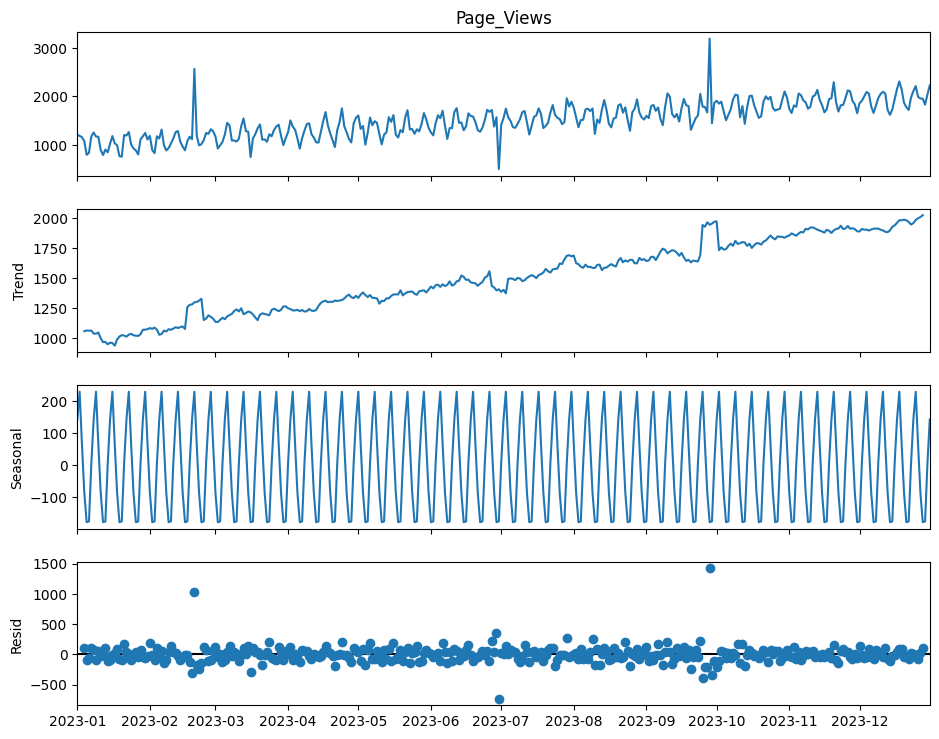

<Figure size 1000x500 with 0 Axes>

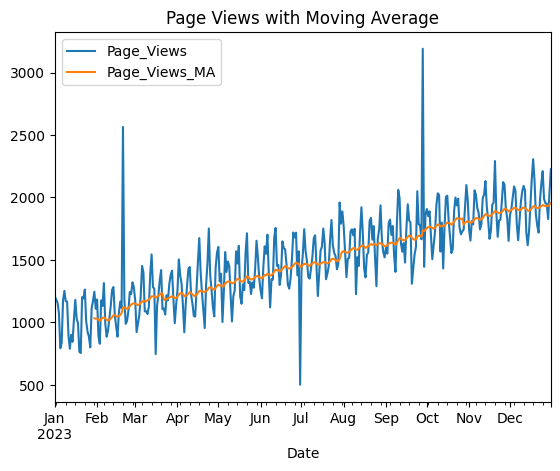

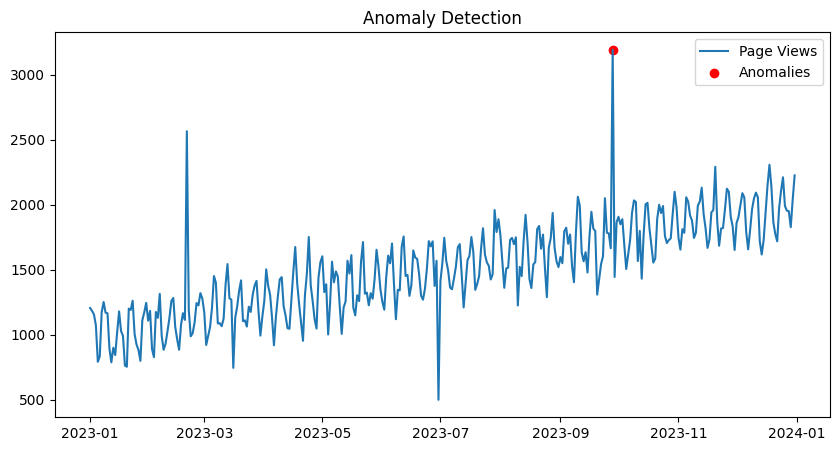

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.seasonal import seasonal_decompose

# Load dataset
data = pd.read_csv('website_traffic.csv', parse_dates=['Date'], index_col='Date')

# Time Series Decomposition
decomposition = seasonal_decompose(data['Page_Views'], model='additive')
fig = decomposition.plot()
fig.set_size_inches(10, 8)
plt.show()

# Moving Average
plt.figure(figsize=(10, 5))
data['Page_Views_MA'] = data['Page_Views'].rolling(window=30).mean()
data[['Page_Views', 'Page_Views_MA']].plot()
plt.title('Page Views with Moving Average')
plt.show()

# Anomaly Detection
plt.figure(figsize=(10, 5))
data['Page_Views_Z'] = (data['Page_Views'] - data['Page_Views'].mean()) / data['Page_Views'].std()
anomalies = data[data['Page_Views_Z'].abs() > 3]

plt.plot(https://colab.research.google.com/$0
         data.index, data['Page_Views'], label='Page Views')
plt.scatter(anomalies.index, anomalies['Page_Views'], color='red', label='Anomalies')
plt.legend()
plt.title('Anomaly Detection')
plt.show()